## Imports

In [7]:
import numpy as np
import matplotlib.pyplot as plt

## Solve For Forces in Each Member

In [8]:
 # Solution Dictionary: Keys = segments, values = solved forces
total_forces = {"AB":0, "BC":0, "AC":0, "R_AX":0, "R_AY":0, "R_CY":0} # PUT INTO YOUR FUNCTION

def truss(theta_A, theta_C, P):

    # Convert degrees to radians
    A = np.radians(theta_A)
    C = np.radians(theta_C)

    # Solution Dictionary: Keys = segments, values = solved forces
    total_forces = {
        "AB": 0,
        "BC": 0,
        "AC": 0,
        "R_AX": 0,
        "R_AY": 0,
        "R_CY": 0
    }

    # Coefficient Matrix
    combined_forces = np.array([
        [ np.cos(A),  1,             0, 1, 0, 0],   # A_x
        [ np.sin(A),  0,             0, 0, 1, 0],   # A_y
        [-np.cos(A),  0,  np.cos(C), 0, 0, 0],      # B_x
        [-np.sin(A),  0, -np.sin(C), 0, 0, 0],      # B_y
        [0,          -1, -np.cos(C), 0, 0, 0],      # C_x
        [0,           0,  np.sin(C), 0, 0, 1]       # C_y
    ])

    # External Loads
    loads = np.array([
        0,
        0,
        0,
        P,
        0,
        0
    ])

    # Solve system
    solutions = np.linalg.solve(combined_forces, loads)

    # Update dictionary
    total_forces["AB"]   = solutions[0]
    total_forces["AC"]   = solutions[1]
    total_forces["BC"]   = solutions[2]
    total_forces["R_AX"] = solutions[3]
    total_forces["R_AY"] = solutions[4]
    total_forces["R_CY"] = solutions[5]

    # Print values
    for key, value in total_forces.items():
        print(f"{key} = {value:.2f} lbs")

    return total_forces

## Find Coordinates of each point

In [9]:
# Coordinates Dictionary of Joints: keys = Joint, values = x, y location
coordinates = {'A': 0, 'B': 0, 'C': 0} # PUT INTO YOUR FUNCTION

def find_coordinates(theta_A, theta_C, length=1):

    A = np.radians(theta_A)
    C = np.radians(theta_C)

    # Find where the two angled members intersect
    x_B = length * np.sin(C) / np.sin(A + C)
    y_B = x_B * np.tan(A)

    x_C = length

    # Coordinates Dictionary of Joints
    coordinates = {
        'A': (0, 0),
        'B': (x_B, y_B),
        'C': (x_C, 0)
    }

    return coordinates

## Graph Truss  **Do Not Change Code**

AB = 1732.05 lbs
BC = 1000.00 lbs
AC = -866.03 lbs
R_AX = 0.00 lbs
R_AY = -1500.00 lbs
R_CY = -500.00 lbs


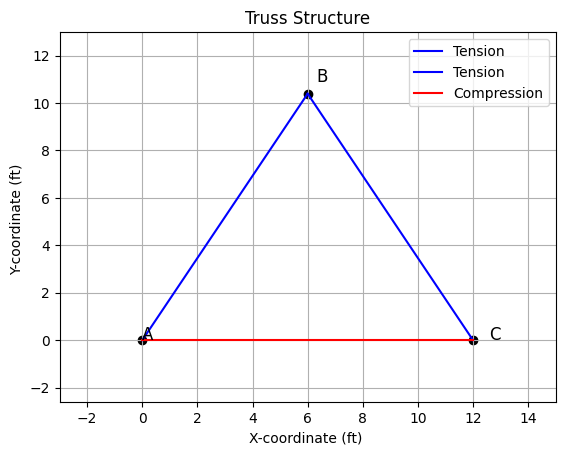

In [12]:
def graph_truss(coordinates, forces):
  # Each member connection with each starting, ending, and force value
  members = {("A", "B"): forces["AB"],
          ("B", "C"): forces["BC"],
          ("A", "C"): forces["AC"]}

  # Graph each member
  for start, end in members:
    force = members[start, end]
    if force > 0:
      color = "blue"  # sets the graphing color to be blue if in tension
      label = "Tension"
    else:
      color = "red" # sets graphing color to be red if in compression
      label = "Compression"
    start_x = coordinates[start][0]
    end_x = coordinates[end][0]
    start_y = coordinates[start][1]
    end_y = coordinates[end][1]
    x_values = [start_x, end_x]
    y_values = [start_y, end_y]
    plt.plot(x_values, y_values, color=color, label=label)


  # Graph each node
  for joint, location in coordinates.items():
    x = location[0]
    y = location[1]
    plt.scatter(x, y, color = "black")  # Black circle marker for joints
    plt.text(x*1.05, y*1.05, joint, fontsize=12) # added +.1 and +.2 for text to not overlap with joints


  # Add legend to lable tension and compression
  plt.legend()
  plt.margins(0.25)
  plt.grid(True)

  # Labels graph and x and y axes
  plt.xlabel("X-coordinate (ft) ")
  plt.ylabel("Y-coordinate (ft) ")
  plt.title("Truss Structure")
  plt.show()

graph_truss(find_coordinates(60,30,12), truss(60,30,-2000))

## Call Functions

In [11]:
forces = truss(45, 45, 1000)
print()

coords = find_coordinates(45, 45, 10)

for point, location in coords.items():
    print(point, location)

AB = -707.11 lbs
BC = -707.11 lbs
AC = 500.00 lbs
R_AX = 0.00 lbs
R_AY = 500.00 lbs
R_CY = 500.00 lbs

A (0, 0)
B (np.float64(7.071067811865475), np.float64(7.071067811865474))
C (10, 0)


AB = 1732.05 lbs
BC = 1000.00 lbs
AC = -866.03 lbs
R_AX = 0.00 lbs
R_AY = -1500.00 lbs
R_CY = -500.00 lbs


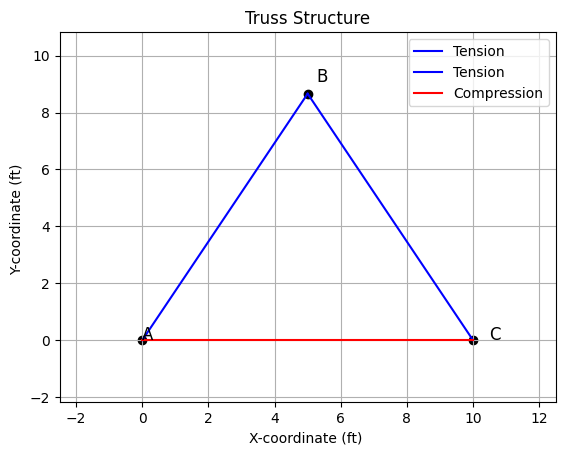

In [14]:
theta_A = 60
theta_C = 30
P = -2000
AC_length = 10

forces = truss(theta_A, theta_C, P)
coordinates = find_coordinates(theta_A, theta_C, AC_length)
graph_truss(coordinates, forces)

AB = 1720.73 lbs
BC = 2457.46 lbs
AC = -1409.54 lbs
R_AX = 0.00 lbs
R_AY = -986.97 lbs
R_CY = -2013.03 lbs


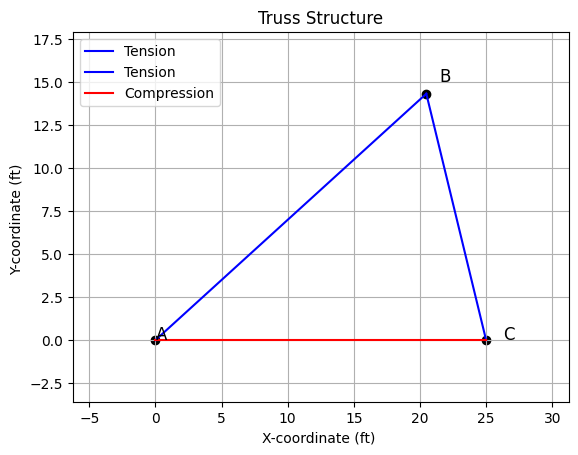

In [16]:
theta_A = 35
theta_C = 55
P = -3000
AC_length = 25

forces = truss(theta_A, theta_C, P)
coordinates = find_coordinates(theta_A, theta_C, AC_length)
graph_truss(coordinates, forces)

AB = -3660.25 lbs
BC = -4482.88 lbs
AC = 3169.87 lbs
R_AX = 0.00 lbs
R_AY = 1830.13 lbs
R_CY = 3169.87 lbs


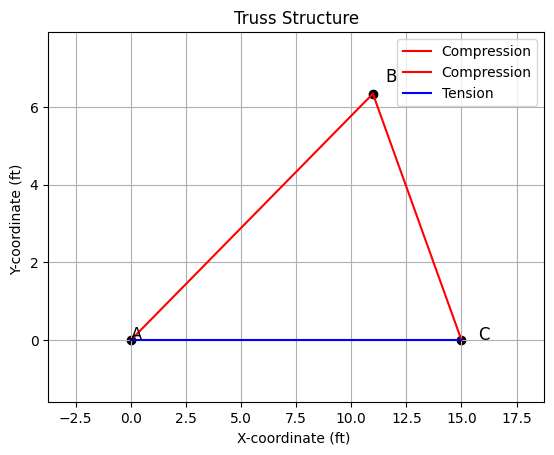

In [18]:
theta_A = 30
theta_C = 45
P = 5000
AC_length = 15

forces = truss(theta_A, theta_C, P)
coordinates = find_coordinates(theta_A, theta_C, AC_length)
graph_truss(coordinates, forces)